<a href="https://colab.research.google.com/github/leonardo-eid/Analise-Desempenho-Escolar_ICMC-Jr/blob/main/exploracaoDeDados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ANÁLISE EXPLORATÓRIA E DESCRITIVA DOS DADOS**

# Limpeza e tratamento

Antes de iniciarmos, vamos fazer a limpeza e tratamento necessário nos dados, com base no notebook passado de 'Pré-processamento e Limpeza dos Dados', isto é, somente aplicar o código necessário conforme o que foi analisado na etapa anterior.

In [ ]:
import pandas as pd

# ==========================================
# 1. SETUP E CARREGAMENTO
# ==========================================
url = 'https://raw.githubusercontent.com/leonardo-eid/Analise-Desempenho-Escolar_ICMC-Jr/refs/heads/main/data/student_performance_interactions.csv'
df = pd.read_csv(url)

# ==========================================
# 2. LIMPEZA E FORMATAÇÃO
# ==========================================
# Removemos o ID, pois não tem valor analítico
df.drop('student_id', axis=1, inplace=True)

# Removemos linhas com erros (valores > 100)
colunas_verificar = ['math_prev_score', 'science_prev_score', 'language_prev_score', 'homework_completion_rate']
for col in colunas_verificar:
    df = df[df[col] <= 100]

# ==========================================
# 3. TRANSFORMAÇÃO DE VARIÁVEIS
# ==========================================
# Mapeamento ordinal para mnater a hierarquia das variáveis de texto
df['parent_education_level'] = df['parent_education_level'].map({'High School': 0, 'Bachelor': 1, 'Master': 2})
df['study_environment'] = df['study_environment'].map({'Noisy': 0, 'Moderate': 1, 'Quiet': 2})
df['grade'] = df['grade'].map({'F': 0, 'D': 1, 'C': 2, 'B': 3, 'A': 4})

print("Base de dados limpa e pronta para AED")
print("Formato final:", df.shape)

Base de dados limpa e pronta para AED
Formato final: (933, 17)


# Box Plot
## "daily study hours" por "pass fail"

Conforme o escopo do projeto, vamos criar o box plot da variável *daily_study_hours* (horas de estudo por dia) por *pass_fail* (se passou ou não de ano) e analisar graficamente o que isso nos diz.



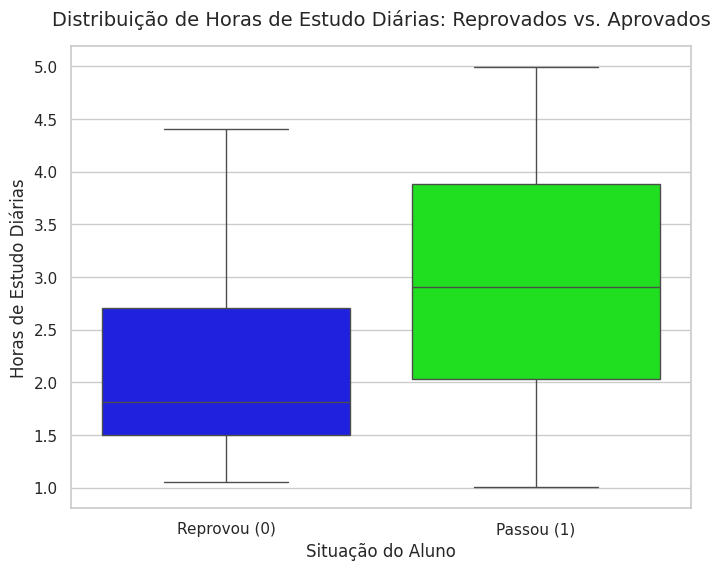

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configura o estilo visual do gráfico
sns.set_theme(style="whitegrid")    # Fundo com linhas de grade
# Define o tamanho da figura (largura, altura)
plt.figure(figsize=(8, 6))

# Criando um dicionário para as cores exigidas
# Azul (#0000FF) para Reprovados (0) e Verde (#00FF00) para Aprovados (1)
cores_ICMCJr = {0: '#0000FF', 1: '#00FF00'}

# Criando o Box Plot
# x = variável categórica (0 ou 1), y = variável numérica contínua
ax = sns.boxplot(
    x='pass_fail',
    y='daily_study_hours',
    data=df,
    hue='pass_fail',
    palette=cores_ICMCJr,
    legend=False
)

# Estilizando títulos e eixos
plt.title('Distribuição de Horas de Estudo Diárias: Reprovados vs. Aprovados', fontsize=14, pad=15)
plt.xlabel('Situação do Aluno', fontsize=12)
plt.ylabel('Horas de Estudo Diárias', fontsize=12)

# Define as posições [0, 1] antes de dar os nomes
ax.set_xticks([0, 1])
# Substitui os números 0 e 1 por rótulos no eixo X
ax.set_xticklabels(['Reprovou (0)', 'Passou (1)'])

# Exibe o gráfico
plt.show()

> **Diferença nas medianas**: observando a linha central de cada caixa, percebemos que a mediana de horas de estudo do grupo reprovado está na faixa de $1.8$ horas diárias, enquanto que a mediana do grupo aprovsdo salta para quase $2.9$ horas. Isso indica visualmente que, em média, quem passa dedica cerca de uma hora a mais por dia aos estudos.

> **Dispersão**: a caixa azul (reprovados) é mais compactada na parte inferior do gráfico, com $75\%$ desses alunos estudando no máximo $2.7$ horas por dia (limite superior da caixa). Em contraste, a base da caixa dos aprovados (os $25\%$ que menos estudam nesse grupo) já começa acima da marca de $2$ horas diárias.

> **Sobreposição e limites**: é importante notarmos que as antenas (bigodes) se sobrepõem. Existem alunos que estudaram mais de $4$ horas por dia e ainda assim reprovaram, assim como existem alunos que estudaram apenas $1$ hora e conseguiram passar. Isso revela que, estatisticamete, o tempo de estudo desloca a probabilidade a favor da aprovação, mas não é o único fator determinante absoluto para o sucesso, justificando a investigação das outras variáveis.

# Heatmap

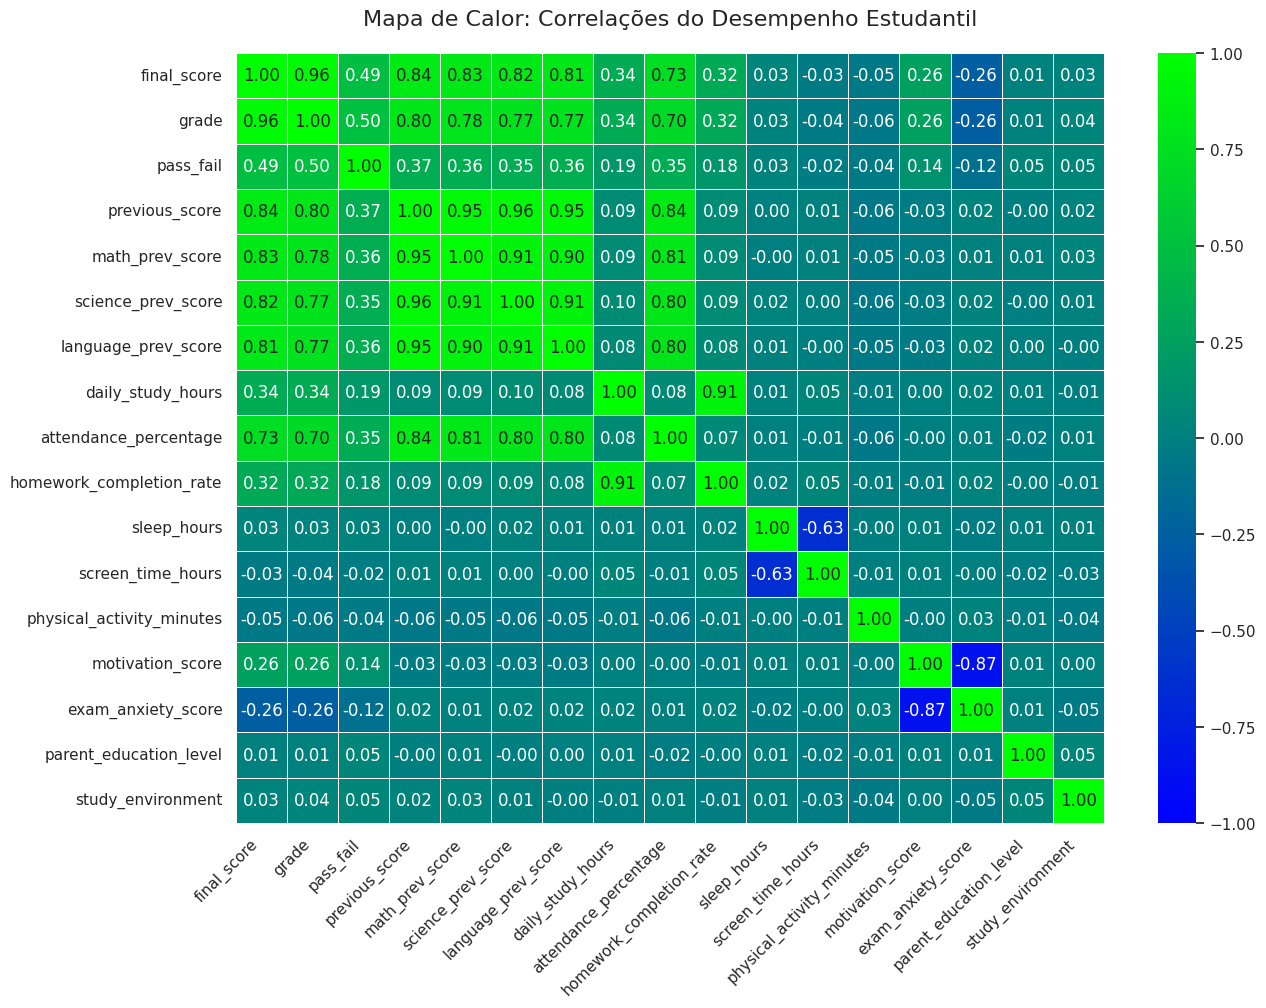

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# Calcula a matriz matematica de correlação de todas as variáveis
matriz_correlacao = df.corr()

cores_ICMCJr = ['#0000FF', '#00FF00'] # vai do azul (menor) pro verde (maior)

cmap_personalizado = LinearSegmentedColormap.from_list("azulVerde", cores_ICMCJr)

plt.figure(figsize=(14, 10))

# Criando o Heatmap
sns.heatmap(
    matriz_correlacao,
    annot=True,                # mostra o número exato da correlação dentro do quadrado
    fmt=".2f",                 # formata para 2 casas decimais
    cmap=cmap_personalizado,   # usa a paleta Azul-Verde
    linewidths=0.5,            # cria uma linha branca separando os quadrados
    vmin=-1, vmax=1            # trava a régua matemática de -1 a 1
)

# Estilizando
plt.title('Mapa de Calor: Correlações do Desempenho Estudantil', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right') # inclina os textos do eixo X

plt.show()

> ### **Correlações Negativas**:

* **Ansiedade x Motivação**: observa-se uma correlação negativa ($-0.87$) entre a ansiedade do aluno (*exam_anxiety_score*) e a motivação escolar (*motivation_score*). Isso indica que, quanto maior o nível de ansiedade do aluno, menor tende a ser o seu engajamento e motivação.

* **Tempo de tela x Horas de sono**: há uma correlação negativa moderada, porém significativa ($-0.63$), entre o tempo de tela (*screen_time_hours*) e as horas de sono (*sleep_hours*). Isso indica que, quanto maior o tempo de tela, menor as horas de sono, demostrando que o uso prolongado de dispositivos afeta no tempo de descanso do aluno.

> ### **Correlações Positivas**:

* **Multidisciplinaridade**: o gráfico evidencia que o sucesso acadêmico costuma ser generalista. Há uma forte correlação entre as notas de diferentes disciplinas. Em sua maioria, alunos com alto desempenho em uma área específica demonstram alto desempenho nas demais também. No entanto, isso também mostra que alunos com baixo desempenho em uma disciplina geralmente demonstram baixo desempenho nas outras.

* **Nota final x Pontuação anterior**: o preditor isolado mais forte da nota final (*final score*) é o desempenho passado do aluno (*previous_score*, com correlação de $0.84$). Ou seja, historicamente, alunos que apresentaram notas altas no ano anterior tendem a manter a excelência, assim como cenários de baixo desempenho tendem a se repetir.

* **Frequência x Pontuações**: A frequência escolar (*attendance_percentage*) correlaciona-se positivamente com todas as métricas de nota do painel. Assim, a simples presença em sala de aula demonstra ser fundamental para o aumento das notas.

* **Taxa de tarefa x Horas de estudo**: existe uma forte relação ($0.91$) entre as horas diárias de estudo (*daily_study_hours*) e a taxa de conclusão de tarefas (*homework_completion_rate*). Portanto, alunos que dedicam mais tempo ao estudo apresentam um volume de entrega e conclusão de tarefas muito superior.

# Distribuição de "final score"

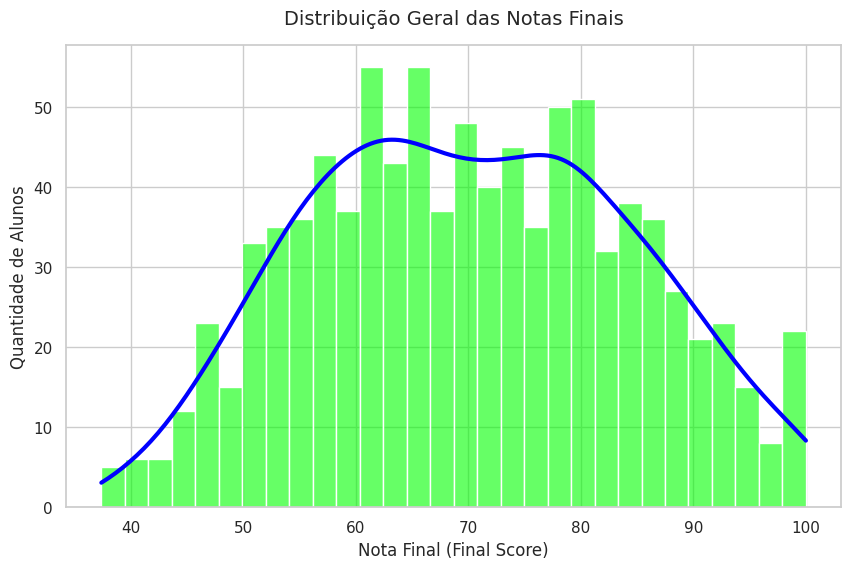

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Criando o Histograma
ax = sns.histplot(
    data=df,
    x='final_score',
    color='#00FF00',           # barras em verde
    kde=True,                  # adiciona a linha de tendência KDE
    line_kws={'linewidth': 3}, # deixaa linha mais grossa
    bins=30,                   # divide as notas em 30 "caixas"
    alpha=0.6,                 # transparência
    edgecolor="white"          # borda branca
)

# Pegamos a primeira linha desenhada e mudamos a cor dela na para azul
if len(ax.lines) > 0:
    ax.lines[0].set_color('#0000FF')

# Estilizando
plt.title('Distribuição Geral das Notas Finais', fontsize=14, pad=15)
plt.xlabel('Nota Final (Final Score)', fontsize=12)
plt.ylabel('Quantidade de Alunos', fontsize=12)

plt.show()

 > Em vez de formar uma única montanha central, o gráfico apresenta **dois picos** diferentes. Isso indica que estamos lidando com uma distribuição bimodal. Ou seja, a turma não é uniforme, ela se divide fortemente em dois grandes grupos de desempenho.

> O primeiro grande grupo de alunos se aglomera na faixa de 60 a 66 pontos, representando a massa de estudantes com desempenho intermediario. O segundo pico surge na faixa dos 78 a 82 pontos, o que demonstra que existe um grupo considerável de alunos com um desempenho de alto nível.

> À esquerda desses dois grandes blocos, notamos uma **pequena cauda** que se arrasta para o lado das notas mais baixas (entre 40 e 50 pontos). Essa elevação bem menor e isolada representa a minoria da turma que enfrentou maiores dificuldades.

# Gráfico de pontos
## "final score" por "attendance percentage"

Vamos para o gráfico de pontos da variável *final_score* (nota final) por *attendance_percentage* (frequência escolar) e analisar graficamente o que isso nos diz.

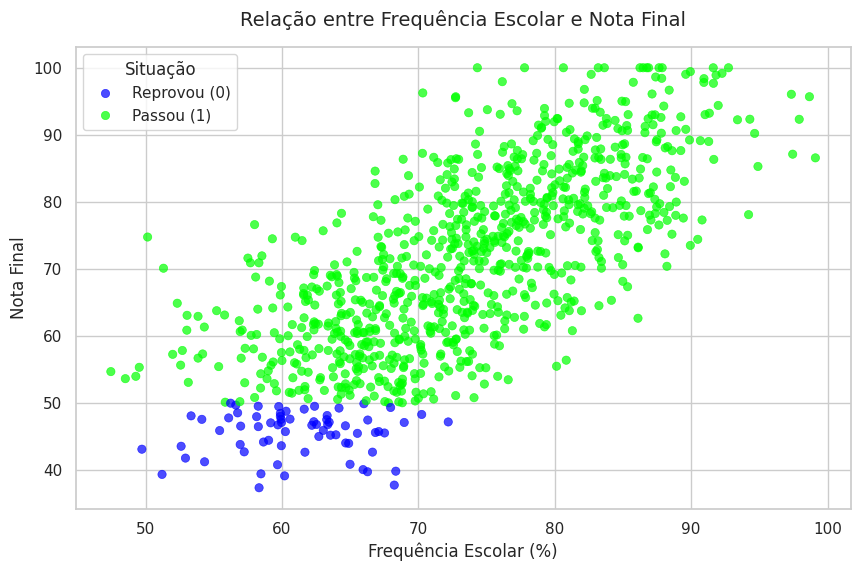

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Mantendo a padronização de cores
cores_ICMCJr = {0: '#0000FF', 1: '#00FF00'}

# Criando o gráfico de dispersão
ax = sns.scatterplot(
    x='attendance_percentage',
    y='final_score',
    data=df,
    hue='pass_fail',         # Pinta os pontos de acordo com a aprovação
    palette=cores_ICMCJr,
    alpha=0.7,               # Deixa os pontos 30% transparentes para vermos onde há aglomeração
    edgecolor=None           # Remove a borda dos pontos para deixar o visual mais limpo
)

# Estilizando
plt.title('Relação entre Frequência Escolar e Nota Final', fontsize=14, pad=15)
plt.xlabel('Frequência Escolar (%)', fontsize=12)
plt.ylabel('Nota Final', fontsize=12)

# Arrumando a legenda
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles=handles, labels=['Reprovou (0)', 'Passou (1)'], title='Situação', loc='upper left')

plt.show()

> **Correlação positiva**: é possível ver que a nuvem de pontos tem uma inclinação ascendente. Isso comprova estatisticamenete que há uma correlação positiva entre as variáveis, ou seja, alunos que freqeuntam mais as aulas tendem a alcançar notas finais maiores.

> **Linha de aprovação**: pela separação por cores, fica evidente que existe uma certa linha horizontal invisível, próxima da nota final $50$. Quase todos os pontos verdes (aprovados) estão concentrados na parte superior do gráfico, enquanto os azuis (reprovados) formam uma massa na parte inferior.

> **Baixa frequência**: analisando a área inferior esquerda do gráfico (baixa frequência e baixa nota), percebe-se uma forte concentração de alunos azuis (reprovados). Isso indica que faltar nas aulas é um forte preditor de uma nota final baixa e, consequentemente, de reprovação.

# Teste Estatístico

In [ ]:
from scipy.stats import shapiro, pearsonr, spearmanr

# Separando as duas colunas que queremos testar
frequencia = df['attendance_percentage']
notas = df['final_score']

# Teste de Normalidade da Shapiro-Wilk
# O p-valor nos diz se a distribuição é normal (p > 0.05) ou não (p < 0.05)
stat_freq, p_freq = shapiro(frequencia)
stat_nota, p_nota = shapiro(notas)

print("===TESTE DE NORMALIDADE (SHAPIRO-WILK)===")
print(f"Frequência - p-valor: {p_freq:.5e}")
print(f"Notas Finais - p-valor: {p_nota:.5e}\n")

===TESTE DE NORMALIDADE (SHAPIRO-WILK)===
Frequência - p-valor: 9.53769e-03
Notas Finais - p-valor: 1.88090e-07



O teste nos devolveu um p-valor inferior a 0.05 tanto para as frequências (0,00953) quanto para as notas (0,000000188). Isso comprova o que já havíamos visto no histograma, ou seja, os dados **não** seguem uma distribuição Normal perfeita.

Portanto, como nossos dados não são normais, o método estatisticamente mais seguro a ser utilizado é a **Correlação de Spearman**

In [ ]:
# Teste de Spearman
rho_spearman, p_spearman = spearmanr(frequencia, notas)

print("===TESTE DE SPEARMAN===")
print(f"Correlação: {rho_spearman:.4f} | p-valor: {p_spearman:.5e}")

===TESTE DE SPEARMAN===
Correlação: 0.7485 | p-valor: 2.97358e-168


O resultado confirmou uma correlação positiva forte (próxima de 0.75) com um p-valor praticamente igual a zero.

O p-valor tão baixo elimina a chance de que essa relação tenha acontecido por mera coincidência. Podemos afirmar que a hipótese visual gerada no gráfico de dispersão é verdadeira, isto é, maiores taxas de frequência estão diretamente ligadas a notas finais mais altas.